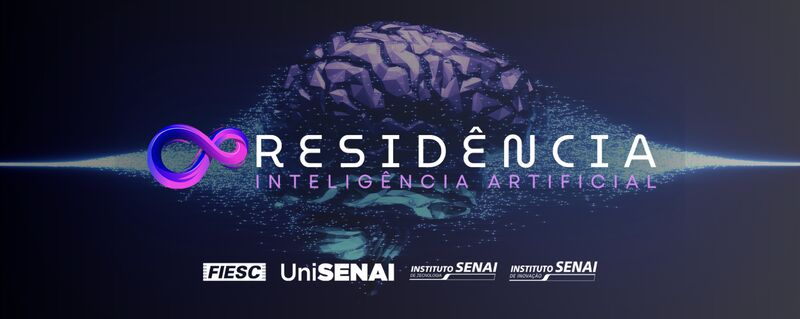

<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>



<h2><b>Unidade Curricular :</b> Visão Computacional</h2>



<h2><b>Professor :</b> Matheus Vanzan</h2>



<h1>Desafio 1 </h1>

---

**Temática**: Modelo para classificação de imagens

**Alunos**: Ana Carolina Dutra Ramos, Camila Gois de Jesus, Guilherme Magalhães Júnior

**Data**: 18/05/2026


---



## **1. Contexto**

Nas aulas 1 e 2, você viu:

- como imagens são representadas (matriz de pixels, canais de cor)
- operações básicas com imagens (transformações, filtros, bordas)
- modelos simples de classificação de imagens com redes Densas e CNN

## **2. Objetivo**

Construir e avaliar uma rede convolucional simples (CNN) para classificação de imagens, usando um dataset do TensorFlow Datasets (TFDS).

Você deverá:

1. Carregar e preparar o dataset a partir do TFDS.  
2. Definir um pipeline de pré-processamento (resize, normalização, etc.).  
3. Criar e treinar uma CNN simples para classificação, ajustando o número de classes conforme o dataset escolhido.
4. Avaliar o desempenho dos modelos e registrar suas conclusões.

## **3. Escolha do dataset**

Entre na página do TensorFlow e escolha um dataset de Classificação de imagens

https://www.tensorflow.org/datasets/catalog/overview?hl=pt-br#image_classification



## **4. Exploração inicial**

* Mostre as informações do dataset escolhido (número de exemplos, número de classes, etc).
* Visualize algumas imagens com seus rótulos (nome da classe).

Veja o exemplo abaixo:

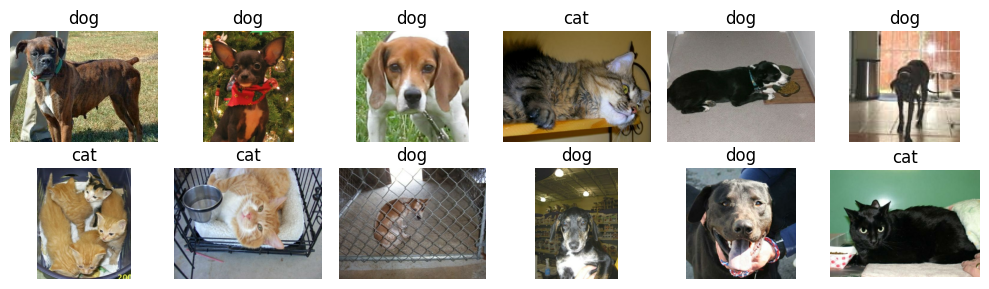

## **5. Pré-processamento**

Defina um pipeline de pré-processamento para as imagens, incluindo:

* redimensionamento para um tamanho fixo (por exemplo, `128 x 128`)
* normalização dos pixels (por exemplo, para a faixa `[0, 1]`)

Processamento adicional
* realize operações de processamento como grayscale, filtros de borda e/ou filtros adicionais para tentar melhorar seus resultados
* deixe como opcional na sua pipeline para poder comparar os resultados

> Dica: crie uma função que recebe um dataset para treino com o modelo, podendo ser o dataset original ou o dataset processado. Dessa forma você evita repetir o mesmo código para um dataset original e um com as imagens processadas.

## **6. Modelo CNN**

Crie uma rede convolucional simples, por exemplo:

* entrada: imagem `(altura, largura, 3)`
* 2 ou 3 blocos `Conv2D + MaxPooling2D`
* 1 camada `Flatten`
* 1 ou 2 camadas `Dense` intermediárias
* camada `Dense` final com N neurônios e ativação `softmax`, sendo N o número de classes

### **6.1. Treinamento e avaliação**

* Treine o modelo nos dois casos abaixo:
   
   1. apenas redimensionamento e normalização
   2. redimensionamento e normalização + filtros a sua escolha

* Varie o número de épocas (por exemplo, 5 a 10) para avaliar o efeito nos resultados.
* Registre a acurácia final para todos os experimentos (no conjunto de teste)

## **7. Análise de resultados**

### 7.1 Apresente todos os experimentos realizados e os resultados encontrados, incluindo, para cada experimento:

* Dataset utilizado (deve ser o mesmo em todos)
* Tamanho das imagens
* Filtros de processamento realizados (se houver)
* Parâmetros adicionais utilizados (épocas, batch_size, etc)

### 7.2 Compare os experimentos relatados na etapa anterior respondendo às seguintes perguntas:

* Os experimentos sem filtros tiveram desempenho melhor, pior ou semelhante os experimentos com filtros adicionais? Explique por que isso pode ter acontecido no dataset escolhido.

* A quantidade de épocas influenciou muito nos resultados? Repita os experimentos que não tiveram pré-proessamento adicional apenas aumentando o númer de épocas. O resultado melhorou ou piorou?

* Considerando os resultados obtidos, o tamanho de imagem escolhido parece adequado para o dataset? Seria melhor trabalhar com uma resolução maior ou menor?

* Se fosse melhorar o desempenho, quais seriam as primeiras alterações que você tentaria na sua pipeline?  
  (ex: aumentar ou diminuir o tamanho da imagem, ajustar a arquitetura da CNN, adicionar data augmentation, escolher outros filtros, alterar learning rate etc.)

* Finalize destacando o que você aprendeu sobre o impacto dos diferentes processamentos no desempenho do modelo.


---

# Solução


In [64]:
import os
import cv2
import random
import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from IPython.display import display

from PIL import Image

from sklearn.model_selection import train_test_split

import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import utils

print(tf.__version__)

2.20.0


# **1) EDA**

In [2]:
# Escolha o dataset no site do TFDS e coloque o nome aqui
dataset_name = 'cats_vs_dogs'

# A MAIORIA dos datasets tem somente "train".
# Se o dataset tiver "test", você troca as SPLITS para ['train', 'test'].

ds, info = tfds.load(
    dataset_name,
    split=['train'],
    with_info=True,
    as_supervised=True,  # retorna (imagem, label)
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.UZS863_4.0.1/cats_vs_dogs-train.tfrecord*...:   0%…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


In [3]:
# Verificando se dataset apresenta divisões (treino / teste)

print(info.splits)

{Split('train'): <SplitInfo num_examples=23262, num_shards=16>}


In [ ]:
'''*Obs: Crashando o Colab


x_list = []
y_list = []

# Converte o dataset TFDS para listas NumPy
# Fazemos esse passo apenas para fins didáticos
# É possivel treinar o modelo diretaemnte com
# datasets do TensorFlow
train_ds = ds[0]
for img, label in tfds.as_numpy(train_ds):
    x_list.append(img)
    y_list.append(label)

## Ainda não podemos transformar em np.array pois
## as imagens podem ter tamanhos diferentes
## Precisamos redimensionar antes

# x = np.array(x_list) # -> erro
# y = np.array(y_list)
# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

len(x_list), len(y_list)'''

(23262, 23262)

In [ ]:
type(x_list)

list

array([[[251, 255, 255],
        [248, 254, 252],
        [242, 246, 245],
        ...,
        [188, 176, 128],
        [142, 132,  81],
        [160, 150,  99]],

       [[247, 253, 251],
        [246, 252, 250],
        [241, 245, 244],
        ...,
        [188, 178, 129],
        [164, 154, 103],
        [176, 166, 115]],

       [[244, 249, 245],
        [244, 249, 245],
        [236, 241, 237],
        ...,
        [197, 187, 138],
        [203, 193, 142],
        [198, 191, 139]],

       ...,

       [[127, 124,  73],
        [149, 146,  95],
        [155, 152, 101],
        ...,
        [165, 170, 140],
        [ 81,  88,  57],
        [ 75,  84,  53]],

       [[167, 164, 113],
        [104, 101,  50],
        [139, 136,  85],
        ...,
        [ 67,  73,  45],
        [ 48,  57,  28],
        [ 38,  49,  19]],

       [[135, 132,  81],
        [ 77,  74,  23],
        [135, 132,  81],
        ...,
        [ 61,  70,  41],
        [ 12,  21,   0],
        [ 64,  75,  45]]], dtype=uint8)
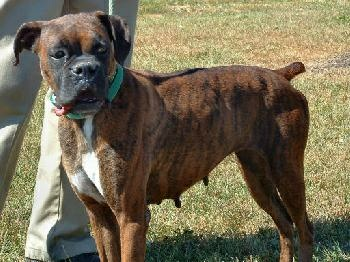

In [ ]:
# Verificando uma imagem

x_list[0]

In [ ]:
# Verificando o rótulo da imagem anterior

y_list[0]

np.int64(1)

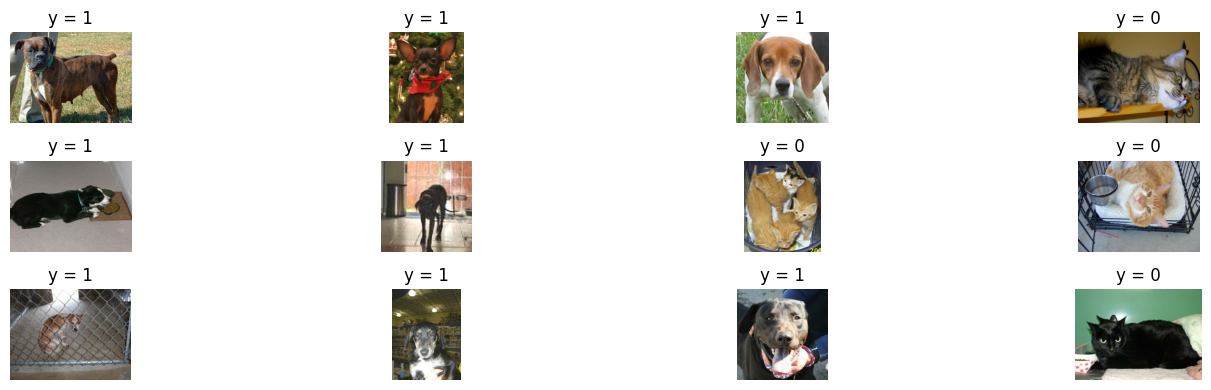

In [ ]:
# Verificando algumas imagens do dataset

plt.figure(figsize=(16, 4))

n = 12
for i in range(n):
    plt.subplot(3, n//3, i+1)
    plt.imshow(x_list[i])
    plt.title(f'y = {y_list[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Verificando a quantidade de rótulos existentes


valores_unicos = np.unique(y_list)
valores_unicos

array([0, 1])

In [ ]:
# Verificando a quantidade de dados existentes para cada rótulo

valores_unicos, quantidade = np.unique(y_list, return_counts=True)

In [ ]:
for valor, qtd in zip(valores_unicos, quantidade):
    print(f"Classe {valor}: {qtd} exemplos")

Classe 0: 11658 exemplos
Classe 1: 11604 exemplos


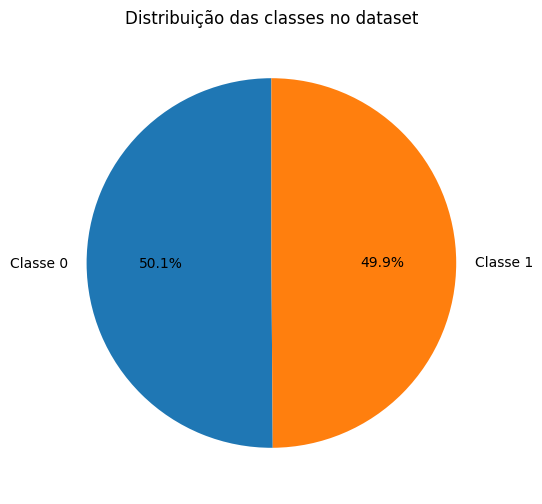

In [ ]:
plt.figure(figsize=(6, 6))

plt.pie(
    quantidade,
    labels=[f'Classe {valor}' for valor in valores_unicos],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribuição das classes no dataset')
plt.show()

# **2) Tratamento dos dados**

In [ ]:
'''
*Obs: Crashando o Colab

# Deixando todas as imagens com o mesmo tamanho

dim = 128

x_redimensionado = []

for imagem in x_list:
    imagem_redimensionada = cv2.resize(imagem, (dim, dim))
    x_redimensionado.append(imagem_redimensionada)

x = np.array(x_redimensionado)
y = np.array(y_list)

print(x.shape)
print(y.shape)'''

'\n*Obs: Crashando o Colab\n\n# Deixando todas as imagens com o mesmo tamanho\n\ndim = 128\n\nx_redimensionado = []\n\nfor imagem in x_list:\n    imagem_redimensionada = cv2.resize(imagem, (dim, dim))\n    x_redimensionado.append(imagem_redimensionada)\n\nx = np.array(x_redimensionado)\ny = np.array(y_list)\n\nprint(x.shape)\nprint(y.shape)'

In [4]:
# Deixando todas as imagens com o mesmo tamanho e normalizados

ds_bruto = ds[0]


IMG_SIZE = 128
BATCH_SIZE = 32


def preprocessar_imagem(img, label):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

ds_tratado = ds_bruto.map(preprocessar_imagem)

In [5]:
type(ds_tratado)

tensorflow.python.data.ops.map_op._MapDataset

In [6]:
# Dataset antes do tratramento

for img, label in ds_bruto.take(4):
    print(img.shape)
    print(img.dtype)
    print(img.numpy().min(), img.numpy().max())
    print(label.numpy())

(262, 350, 3)
<dtype: 'uint8'>
0 255
1
(409, 336, 3)
<dtype: 'uint8'>
0 255
1
(493, 500, 3)
<dtype: 'uint8'>
0 255
1
(375, 500, 3)
<dtype: 'uint8'>
0 255
0


In [7]:
# Dataset pós tratamento


for img, label in ds_tratado.take(4):
    print(img.shape)
    print(img.dtype)
    print(img.numpy().min(), img.numpy().max())
    print(label.numpy())

(128, 128, 3)
<dtype: 'float32'>
0.0 1.0
1
(128, 128, 3)
<dtype: 'float32'>
0.0007132736 1.0
1
(128, 128, 3)
<dtype: 'float32'>
0.0 1.0
1
(128, 128, 3)
<dtype: 'float32'>
0.0 0.9992137
0


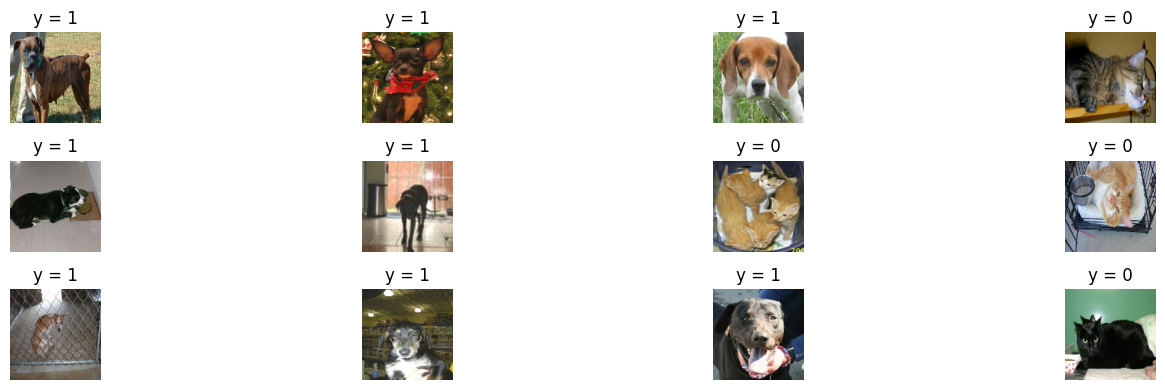

In [8]:
plt.figure(figsize=(16, 4))

n = 12

for i, (img, label) in enumerate(ds_tratado.take(n)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f'y = {label.numpy()}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Criando o dataset em escala de cinza

def converter_para_gray(img, label):
    img_gray = tf.image.rgb_to_grayscale(img)
    return img_gray, label

ds_tratado_grey_scale = ds_tratado.map(converter_para_gray)

In [10]:
# Criando o dataset de bordas (usando Sobel)


def converter_para_sobel(img, label):
    # Converte RGB para escala de cinza
    img_gray = tf.image.rgb_to_grayscale(img)

    # Adiciona dimensão de batch: (128, 128, 1) -> (1, 128, 128, 1)
    img_gray_batch = tf.expand_dims(img_gray, axis=0)

    # Aplica Sobel
    sobel = tf.image.sobel_edges(img_gray_batch)

    # Remove dimensão de batch
    sobel = tf.squeeze(sobel, axis=0)

    # Separa derivadas em x e y
    sobel_x = sobel[..., 0]
    sobel_y = sobel[..., 1]

    # Calcula magnitude da borda
    magnitude = tf.sqrt(tf.square(sobel_x) + tf.square(sobel_y))

    # Normaliza para 0 a 1
    magnitude = magnitude / (tf.reduce_max(magnitude) + 1e-8)

    return magnitude, label


ds_tratado_borda = ds_tratado.map(converter_para_sobel)

In [11]:
# Criando o dataset de outline


def converter_para_outline(img, label):
    # Converte RGB para escala de cinza
    img_gray = tf.image.rgb_to_grayscale(img)

    # Adiciona dimensão de batch: (128, 128, 1) -> (1, 128, 128, 1)
    img_gray = tf.expand_dims(img_gray, axis=0)

    # Aplica Sobel
    sobel = tf.image.sobel_edges(img_gray)

    # Remove dimensão de batch: (1, 128, 128, 1, 2) -> (128, 128, 1, 2)
    sobel = tf.squeeze(sobel, axis=0)

    # Separa gradientes x e y
    sobel_x = sobel[..., 0]
    sobel_y = sobel[..., 1]

    # Calcula magnitude da borda
    magnitude = tf.sqrt(tf.square(sobel_x) + tf.square(sobel_y))

    # Remove dimensão extra: (128, 128, 1) -> (128, 128)
    magnitude = tf.squeeze(magnitude, axis=-1)

    # Normaliza para 0 a 1
    magnitude = magnitude / (tf.reduce_max(magnitude) + 1e-8)

    # Cria outline binário
    outline = tf.where(magnitude > 0.25, 1.0, 0.0)

    # Volta para formato de imagem com canal: (128, 128) -> (128, 128, 1)
    outline = tf.expand_dims(outline, axis=-1)

    return outline, label


ds_tratado_outline = ds_tratado.map(converter_para_outline)

# **3) Split**

In [12]:
# Verificando número de dados do dataset

num_exemplos = ds_tratado.cardinality().numpy()
print(num_exemplos)

23262


In [13]:
# Definindo tamanho do dataset de treino/teste

num_train = int(num_exemplos * 0.8)
num_train

18609

In [14]:
# Split dataset RGB

ds_rgb_train = ds_tratado.take(num_train)
ds_rgb_test = ds_tratado.skip(num_train)

In [15]:
# Split dataset escala de cinza

ds_gray_train = ds_tratado_grey_scale.take(num_train)
ds_gray_test = ds_tratado_grey_scale.skip(num_train)

In [16]:
# Split dataset de bordas

ds_sobel_train = ds_tratado_borda.take(num_train)
ds_sobel_test = ds_tratado_borda.skip(num_train)

In [17]:
# Split dataset de outline

ds_outline_train = ds_tratado_outline.take(num_train)
ds_outline_test = ds_tratado_outline.skip(num_train)

In [18]:
# Confirmando a dimensão do dado de entrada do dataset RGB

img_shape = ds_rgb_train.element_spec[0].shape
img_shape

TensorShape([128, 128, 3])

In [19]:
# Confirmando a dimensão do dado de entrada do dataset escala de cinza

img_shape = ds_gray_train.element_spec[0].shape
img_shape

TensorShape([128, 128, 1])

In [20]:
# Confirmando a dimensão do dado de entrada do dataset de bordas

img_shape = ds_sobel_train.element_spec[0].shape
img_shape

TensorShape([128, 128, 1])

In [21]:
# Confirmando a dimensão do dado de entrada do dataset de outline

img_shape = ds_outline_train.element_spec[0].shape
img_shape

TensorShape([128, 128, 1])

# **4) Treinando o modelo**

In [22]:
# Ver se o TF enxerga alguma GPU
print(tf.config.list_physical_devices('GPU'))

# Nome do device padrão (vazio se não tiver GPU)
print(tf.test.gpu_device_name())

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
/device:GPU:0


## a) Dataset RGB -  baseline

In [23]:
model_rgb = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_rgb.summary()

model_rgb.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
BATCH_SIZE = 16

ds_rgb_train_batch = ds_rgb_train.batch(BATCH_SIZE)
ds_rgb_test_batch = ds_rgb_test.batch(BATCH_SIZE)

In [25]:
%%time

history_rgb = model_rgb.fit(
    ds_rgb_train_batch,
    validation_data=ds_rgb_test_batch,
    epochs=5
)

Epoch 1/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 55s 43ms/step - accuracy: 0.6008 - loss: 0.6571 - val_accuracy: 0.6609 - val_loss: 0.6184
Epoch 2/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 47s 40ms/step - accuracy: 0.6705 - loss: 0.6067 - val_accuracy: 0.7127 - val_loss: 0.5651
Epoch 3/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.7041 - loss: 0.5704 - val_accuracy: 0.7296 - val_loss: 0.5416
Epoch 4/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 45s 39ms/step - accuracy: 0.7246 - loss: 0.5447 - val_accuracy: 0.7485 - val_loss: 0.5162
Epoch 5/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.7451 - loss: 0.5181 - val_accuracy: 0.7651 - val_loss: 0.4897
CPU times: user 6min 25s, sys: 21.3 s, total: 6min 46s
Wall time: 3min 59s


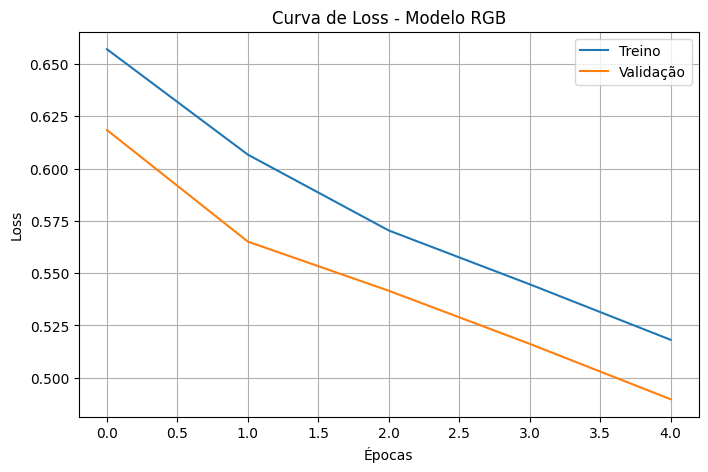

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(history_rgb.history['loss'], label='Treino')
plt.plot(history_rgb.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo RGB')
plt.legend()
plt.grid(True)
plt.show()

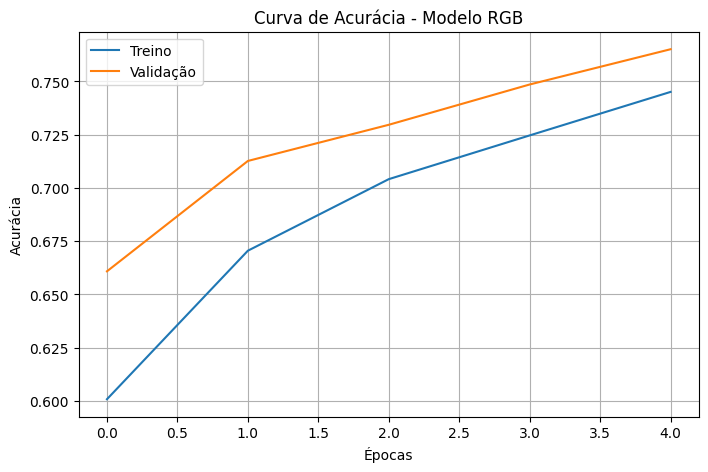

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history_rgb.history['accuracy'], label='Treino')
plt.plot(history_rgb.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo RGB')
plt.legend()
plt.grid(True)
plt.show()

In [28]:
acc_treino_final = history_rgb.history['accuracy'][-1]
acc_teste_final = history_rgb.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final:.4f}")

Acurácia final no treino: 0.7451
Acurácia final no teste/validação: 0.7651


### - 10 épocas

In [29]:
%%time

history_rgb_10 = model_rgb.fit(
    ds_rgb_train_batch,
    validation_data=ds_rgb_test_batch,
    epochs=10
)

Epoch 1/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 39ms/step - accuracy: 0.7647 - loss: 0.4921 - val_accuracy: 0.7866 - val_loss: 0.4677
Epoch 2/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 45s 39ms/step - accuracy: 0.7844 - loss: 0.4607 - val_accuracy: 0.7915 - val_loss: 0.4456
Epoch 3/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.8062 - loss: 0.4263 - val_accuracy: 0.8014 - val_loss: 0.4244
Epoch 4/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 45s 39ms/step - accuracy: 0.8237 - loss: 0.3942 - val_accuracy: 0.8227 - val_loss: 0.3951
Epoch 5/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.8399 - loss: 0.3627 - val_accuracy: 0.8384 - val_loss: 0.3635
Epoch 6/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 51s 44ms/step - accuracy: 0.8542 - loss: 0.3340 - val_accuracy: 0.8485 - val_loss: 0.3432
Epoch 7/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 54s 47ms/step - accuracy: 0.8676 - loss: 0.3085 - val_accuracy: 0.8521 - val_loss: 0.3320
Epoch 8/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.8797 -

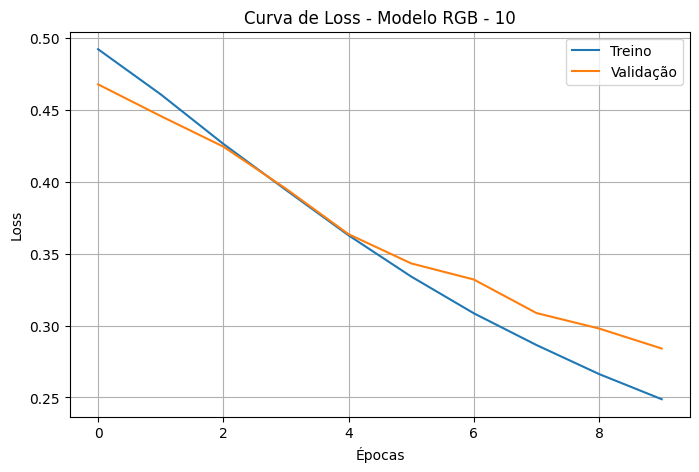

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history_rgb_10.history['loss'], label='Treino')
plt.plot(history_rgb_10.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo RGB - 10')
plt.legend()
plt.grid(True)
plt.show()

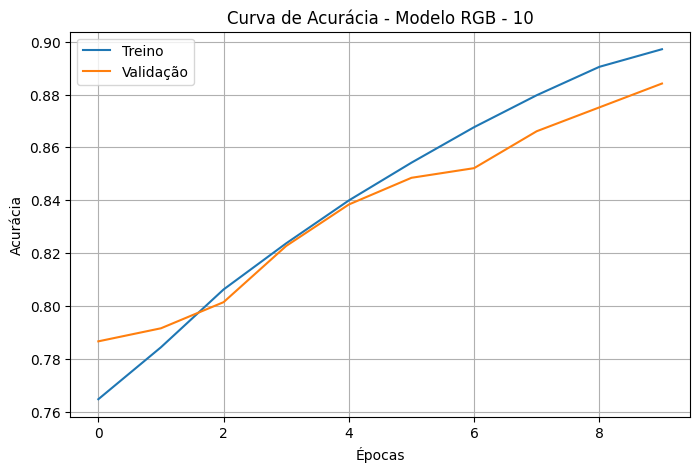

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history_rgb_10.history['accuracy'], label='Treino')
plt.plot(history_rgb_10.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo RGB - 10')
plt.legend()
plt.grid(True)
plt.show()

In [32]:
acc_treino_final = history_rgb_10.history['accuracy'][-1]
acc_teste_final = history_rgb_10.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final:.4f}")

Acurácia final no treino: 0.8971
Acurácia final no teste/validação: 0.8842


## b) Dataset escala de cinza

In [33]:
model_gray = keras.Sequential([
    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_gray.summary()

model_gray.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
BATCH_SIZE = 16

ds_gray_train_batch = ds_gray_train.batch(BATCH_SIZE)
ds_gray_test_batch = ds_gray_test.batch(BATCH_SIZE)

In [35]:
%%time

history_gray = model_gray.fit(
    ds_gray_train_batch,
    validation_data=ds_gray_test_batch,
    epochs=5
)

Epoch 1/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 62s 51ms/step - accuracy: 0.5867 - loss: 0.6696 - val_accuracy: 0.6600 - val_loss: 0.6329
Epoch 2/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.6634 - loss: 0.6173 - val_accuracy: 0.6886 - val_loss: 0.5983
Epoch 3/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 57s 49ms/step - accuracy: 0.6910 - loss: 0.5864 - val_accuracy: 0.7008 - val_loss: 0.5762
Epoch 4/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 55s 47ms/step - accuracy: 0.7148 - loss: 0.5585 - val_accuracy: 0.7279 - val_loss: 0.5447
Epoch 5/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.7429 - loss: 0.5283 - val_accuracy: 0.7468 - val_loss: 0.5152
CPU times: user 7min 39s, sys: 29.9 s, total: 8min 8s
Wall time: 5min 12s


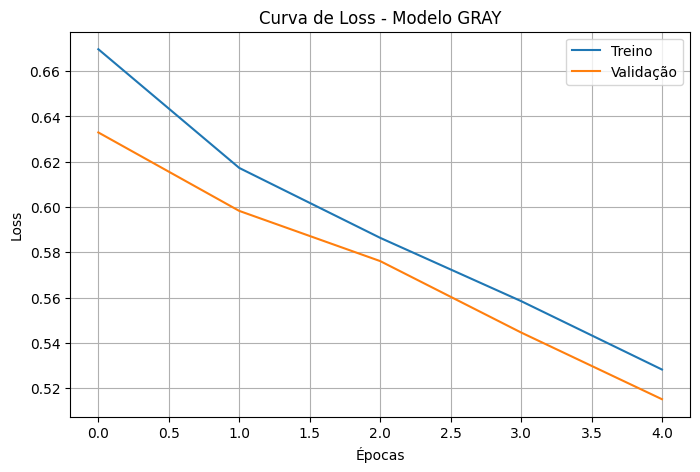

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history_gray.history['loss'], label='Treino')
plt.plot(history_gray.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo GRAY')
plt.legend()
plt.grid(True)
plt.show()

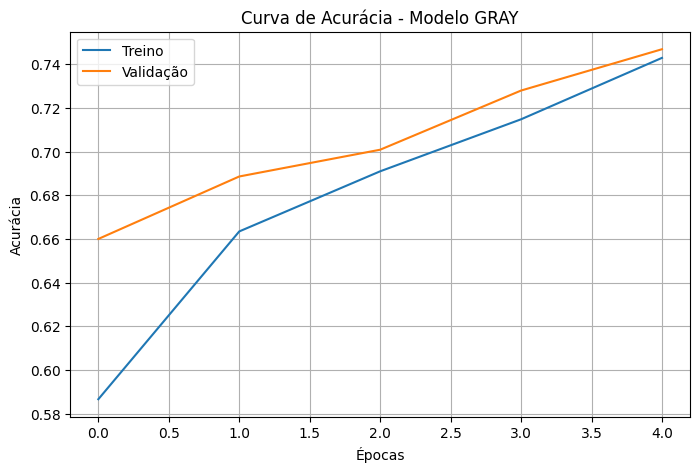

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history_gray.history['accuracy'], label='Treino')
plt.plot(history_gray.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo GRAY')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
acc_treino_final = history_gray.history['accuracy'][-1]
acc_teste_final = history_gray.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final:.4f}")

Acurácia final no treino: 0.7429
Acurácia final no teste/validação: 0.7468


### - 10 épocas

In [39]:
%%time

history_gray_10 = model_gray.fit(
    ds_gray_train_batch,
    validation_data=ds_gray_test_batch,
    epochs=10
)

Epoch 1/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 68s 58ms/step - accuracy: 0.7684 - loss: 0.4912 - val_accuracy: 0.7412 - val_loss: 0.5196
Epoch 2/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.7940 - loss: 0.4489 - val_accuracy: 0.7741 - val_loss: 0.4761
Epoch 3/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.8159 - loss: 0.4113 - val_accuracy: 0.7862 - val_loss: 0.4539
Epoch 4/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.8357 - loss: 0.3760 - val_accuracy: 0.7924 - val_loss: 0.4390
Epoch 5/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 55s 47ms/step - accuracy: 0.8517 - loss: 0.3456 - val_accuracy: 0.8098 - val_loss: 0.4079
Epoch 6/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 56s 48ms/step - accuracy: 0.8645 - loss: 0.3201 - val_accuracy: 0.8221 - val_loss: 0.3820
Epoch 7/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 55s 47ms/step - accuracy: 0.8768 - loss: 0.2955 - val_accuracy: 0.8319 - val_loss: 0.3669
Epoch 8/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 54s 47ms/step - accuracy: 0.8864 -

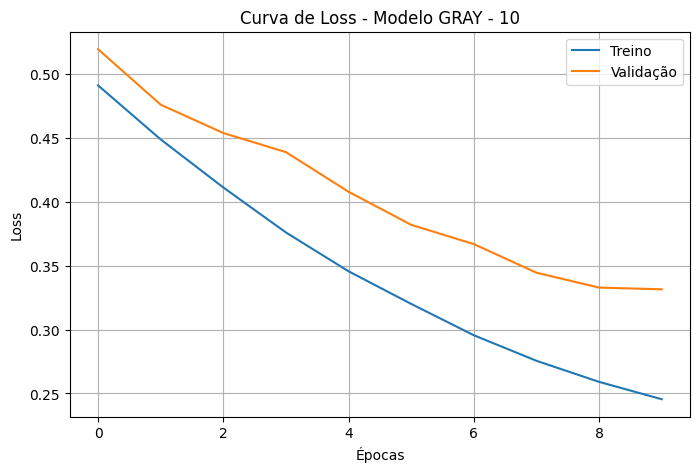

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history_gray_10.history['loss'], label='Treino')
plt.plot(history_gray_10.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo GRAY - 10')
plt.legend()
plt.grid(True)
plt.show()

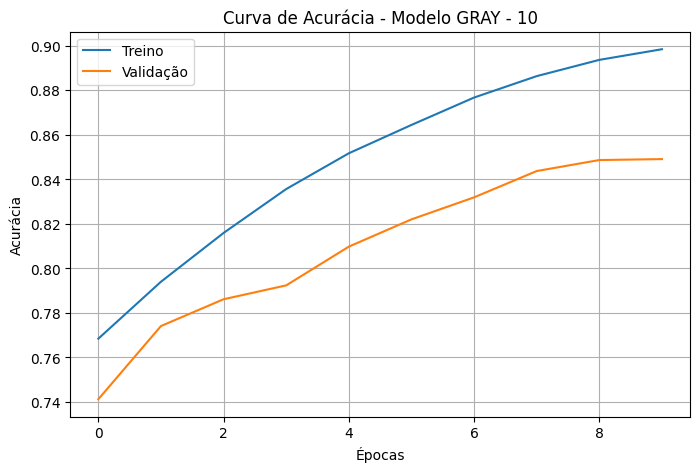

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history_gray_10.history['accuracy'], label='Treino')
plt.plot(history_gray_10.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo GRAY - 10')
plt.legend()
plt.grid(True)
plt.show()

In [42]:
acc_treino_final_10 = history_gray_10.history['accuracy'][-1]
acc_teste_final_10 = history_gray_10.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final_10:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final_10:.4f}")

Acurácia final no treino: 0.8985
Acurácia final no teste/validação: 0.8491


## c) Dataset de bordas

In [43]:
model_sobel = keras.Sequential([
    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_sobel.summary()

model_sobel.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
BATCH_SIZE = 16

ds_sobel_train_batch = ds_sobel_train.batch(BATCH_SIZE)
ds_sobel_test_batch = ds_sobel_test.batch(BATCH_SIZE)

In [45]:
%%time

history_sobel = model_sobel.fit(
    ds_sobel_train_batch,
    validation_data=ds_sobel_test_batch,
    epochs=5
)

Epoch 1/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 147s 124ms/step - accuracy: 0.5980 - loss: 0.6628 - val_accuracy: 0.6639 - val_loss: 0.6192
Epoch 2/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 199s 123ms/step - accuracy: 0.6613 - loss: 0.6212 - val_accuracy: 0.6860 - val_loss: 0.5938
Epoch 3/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 149s 128ms/step - accuracy: 0.6927 - loss: 0.5897 - val_accuracy: 0.7069 - val_loss: 0.5709
Epoch 4/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 146s 125ms/step - accuracy: 0.7184 - loss: 0.5597 - val_accuracy: 0.7535 - val_loss: 0.5279
Epoch 5/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 150s 129ms/step - accuracy: 0.7460 - loss: 0.5209 - val_accuracy: 0.7791 - val_loss: 0.4920
CPU times: user 20min 21s, sys: 37.2 s, total: 20min 58s
Wall time: 13min 10s


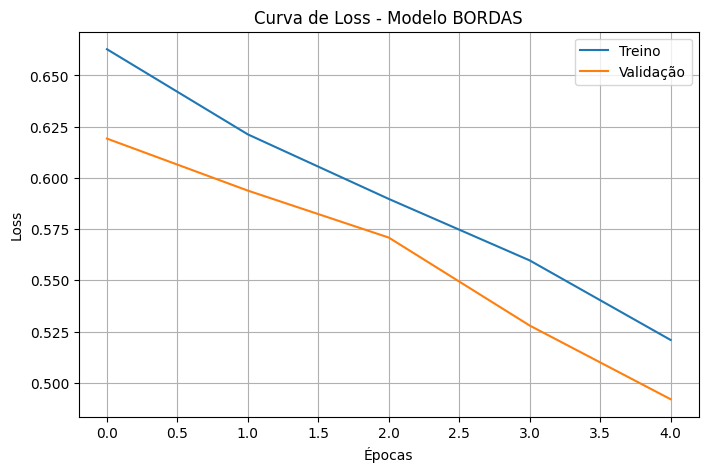

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(history_sobel.history['loss'], label='Treino')
plt.plot(history_sobel.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo BORDAS')
plt.legend()
plt.grid(True)
plt.show()

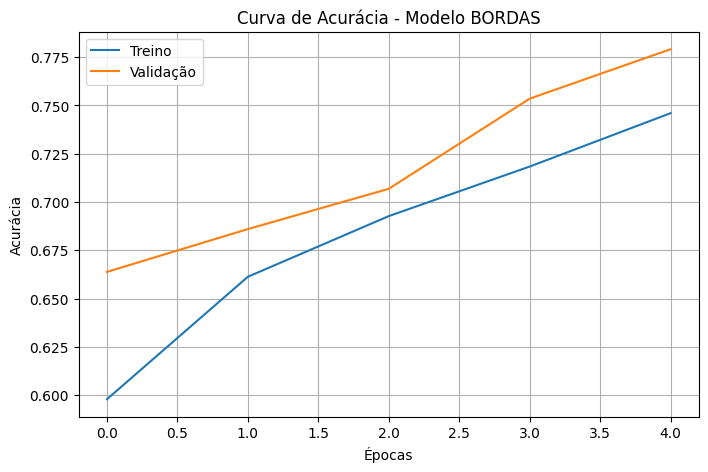

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(history_sobel.history['accuracy'], label='Treino')
plt.plot(history_sobel.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo BORDAS')
plt.legend()
plt.grid(True)
plt.show()

In [48]:
acc_treino_final = history_sobel.history['accuracy'][-1]
acc_teste_final = history_sobel.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final:.4f}")

Acurácia final no treino: 0.7460
Acurácia final no teste/validação: 0.7791


### - 10 épocas

In [49]:
%%time

history_sobel_10 = model_sobel.fit(
    ds_sobel_train_batch,
    validation_data=ds_sobel_test_batch,
    epochs=10
)

Epoch 1/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 143s 123ms/step - accuracy: 0.7697 - loss: 0.4856 - val_accuracy: 0.7907 - val_loss: 0.4666
Epoch 2/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 141s 121ms/step - accuracy: 0.7846 - loss: 0.4576 - val_accuracy: 0.7937 - val_loss: 0.4498
Epoch 3/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 142s 122ms/step - accuracy: 0.7995 - loss: 0.4361 - val_accuracy: 0.7973 - val_loss: 0.4377
Epoch 4/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 143s 123ms/step - accuracy: 0.8089 - loss: 0.4188 - val_accuracy: 0.8003 - val_loss: 0.4292
Epoch 5/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 148s 127ms/step - accuracy: 0.8182 - loss: 0.4018 - val_accuracy: 0.7991 - val_loss: 0.4280
Epoch 6/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 141s 121ms/step - accuracy: 0.8262 - loss: 0.3851 - val_accuracy: 0.7991 - val_loss: 0.4224
Epoch 7/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 141s 121ms/step - accuracy: 0.8365 - loss: 0.3696 - val_accuracy: 0.8059 - val_loss: 0.4122
Epoch 8/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 143s 123ms/step - ac

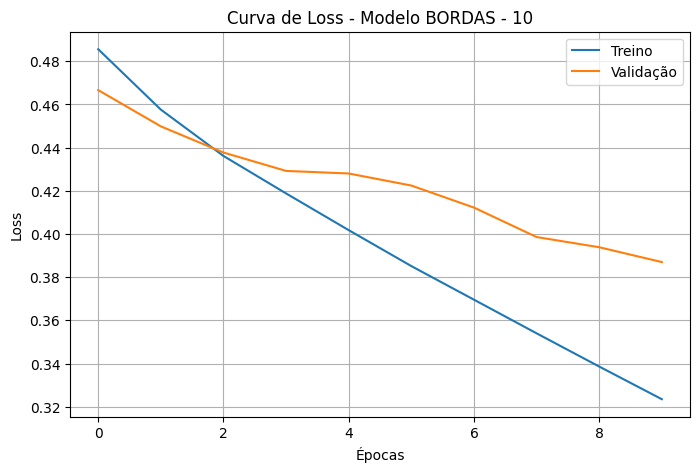

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(history_sobel_10.history['loss'], label='Treino')
plt.plot(history_sobel_10.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo BORDAS - 10')
plt.legend()
plt.grid(True)
plt.show()

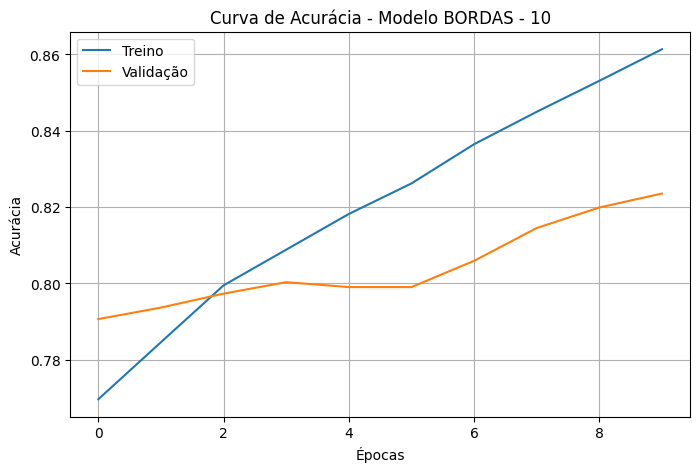

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(history_sobel_10.history['accuracy'], label='Treino')
plt.plot(history_sobel_10.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo BORDAS - 10')
plt.legend()
plt.grid(True)
plt.show()

In [52]:
acc_treino_final_10 = history_sobel_10.history['accuracy'][-1]
acc_teste_final_10 = history_sobel_10.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final_10:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final_10:.4f}")

Acurácia final no treino: 0.8614
Acurácia final no teste/validação: 0.8236


## d) Dataset de outline

In [53]:
model_outline = keras.Sequential([
    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_outline.summary()

model_outline.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,993 (394.50 KB)

 Trainable params: 100,993 (394.50 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
BATCH_SIZE = 16

ds_outline_train_batch = ds_outline_train.batch(BATCH_SIZE)
ds_outline_test_batch = ds_outline_test.batch(BATCH_SIZE)

In [55]:
%%time

history_outline = model_outline.fit(
    ds_outline_train_batch,
    validation_data=ds_outline_test_batch,
    epochs=5
)

Epoch 1/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 149s 125ms/step - accuracy: 0.5950 - loss: 0.6645 - val_accuracy: 0.6263 - val_loss: 0.6385
Epoch 2/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 145s 124ms/step - accuracy: 0.6312 - loss: 0.6404 - val_accuracy: 0.6293 - val_loss: 0.6339
Epoch 3/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 150s 129ms/step - accuracy: 0.6421 - loss: 0.6327 - val_accuracy: 0.6490 - val_loss: 0.6218
Epoch 4/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 146s 125ms/step - accuracy: 0.6594 - loss: 0.6191 - val_accuracy: 0.6735 - val_loss: 0.5999
Epoch 5/5
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 148s 127ms/step - accuracy: 0.6901 - loss: 0.5875 - val_accuracy: 0.7051 - val_loss: 0.5671
CPU times: user 20min 41s, sys: 38.3 s, total: 21min 19s
Wall time: 12min 16s


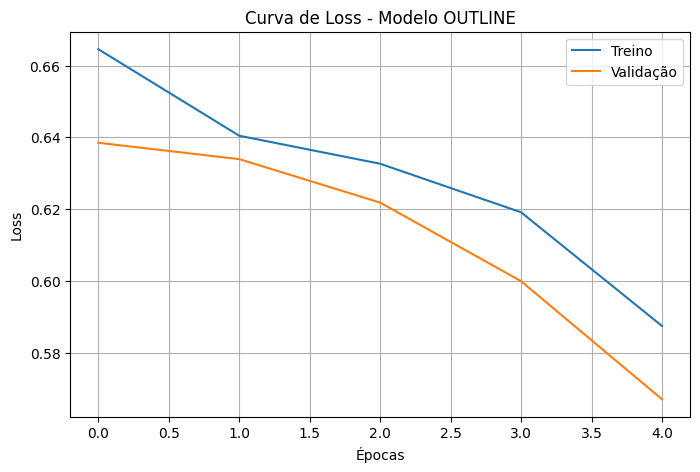

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(history_outline.history['loss'], label='Treino')
plt.plot(history_outline.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo OUTLINE')
plt.legend()
plt.grid(True)
plt.show()

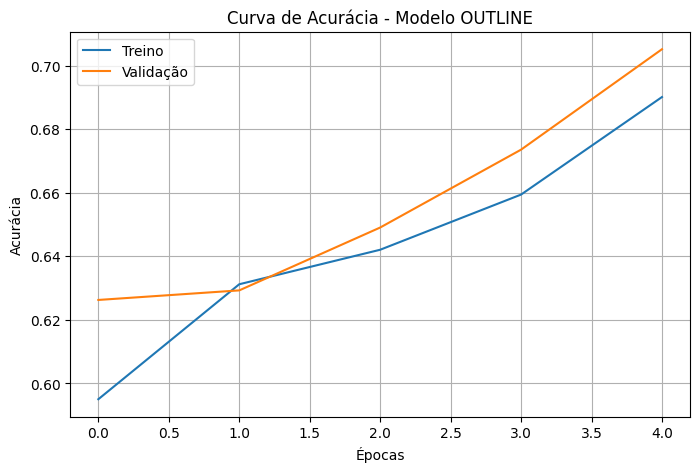

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(history_outline.history['accuracy'], label='Treino')
plt.plot(history_outline.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo OUTLINE')
plt.legend()
plt.grid(True)
plt.show()

In [58]:
acc_treino_final = history_outline.history['accuracy'][-1]
acc_teste_final = history_outline.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final:.4f}")

Acurácia final no treino: 0.6901
Acurácia final no teste/validação: 0.7051


### - 10 épocas

In [59]:
%%time

history_outline_10 = model_outline.fit(
    ds_outline_train_batch,
    validation_data=ds_outline_test_batch,
    epochs=10
)

Epoch 1/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 146s 126ms/step - accuracy: 0.7185 - loss: 0.5548 - val_accuracy: 0.7273 - val_loss: 0.5400
Epoch 2/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 145s 125ms/step - accuracy: 0.7402 - loss: 0.5248 - val_accuracy: 0.7464 - val_loss: 0.5118
Epoch 3/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 147s 127ms/step - accuracy: 0.7562 - loss: 0.4998 - val_accuracy: 0.7556 - val_loss: 0.4951
Epoch 4/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 144s 124ms/step - accuracy: 0.7704 - loss: 0.4783 - val_accuracy: 0.7677 - val_loss: 0.4854
Epoch 5/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 207s 128ms/step - accuracy: 0.7839 - loss: 0.4590 - val_accuracy: 0.7724 - val_loss: 0.4801
Epoch 6/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 144s 123ms/step - accuracy: 0.7952 - loss: 0.4413 - val_accuracy: 0.7791 - val_loss: 0.4760
Epoch 7/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 145s 124ms/step - accuracy: 0.8054 - loss: 0.4236 - val_accuracy: 0.7789 - val_loss: 0.4758
Epoch 8/10
1164/1164 ━━━━━━━━━━━━━━━━━━━━ 143s 123ms/step - ac

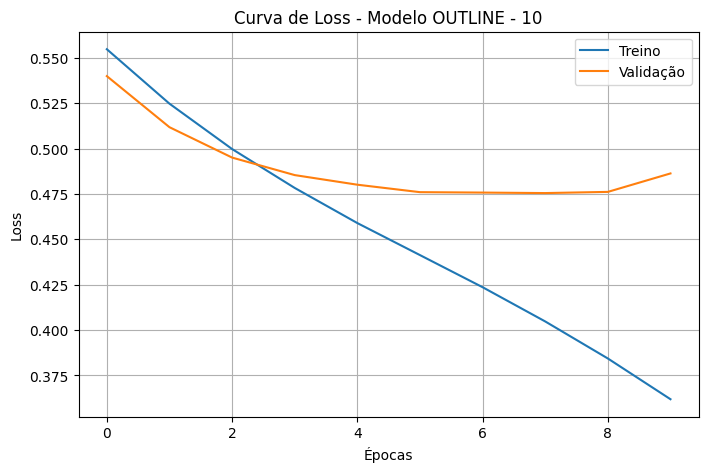

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(history_outline_10.history['loss'], label='Treino')
plt.plot(history_outline_10.history['val_loss'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.title('Curva de Loss - Modelo OUTLINE - 10')
plt.legend()
plt.grid(True)
plt.show()

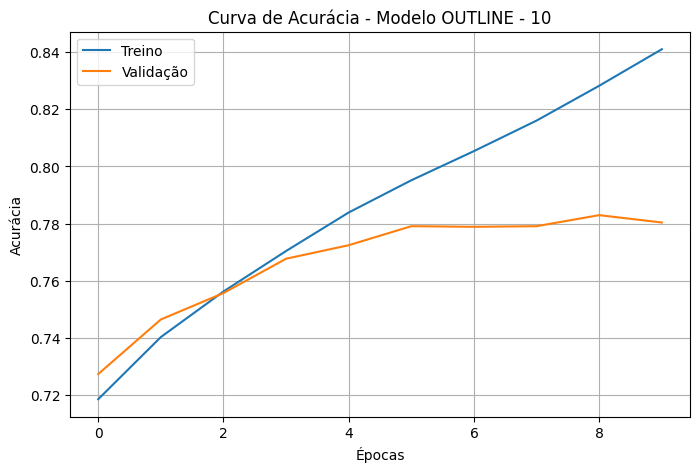

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(history_outline_10.history['accuracy'], label='Treino')
plt.plot(history_outline_10.history['val_accuracy'], label='Validação')

plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.title('Curva de Acurácia - Modelo OUTLINE - 10')
plt.legend()
plt.grid(True)
plt.show()

In [62]:
acc_treino_final_10 = history_outline_10.history['accuracy'][-1]
acc_teste_final_10 = history_outline_10.history['val_accuracy'][-1]

print(f"Acurácia final no treino: {acc_treino_final_10:.4f}")
print(f"Acurácia final no teste/validação: {acc_teste_final_10:.4f}")

Acurácia final no treino: 0.8410
Acurácia final no teste/validação: 0.7804


## Resultado final

In [69]:
resultados = pd.DataFrame({
    'Modelo': [
        'RGB - 5 épocas',
        'RGB - 10 épocas',
        'Escala de cinza - 5 épocas',
        'Escala de cinza - 10 épocas',
        'Sobel - 5 épocas',
        'Sobel - 10 épocas',
        'Outline - 5 épocas',
        'Outline - 10 épocas'
    ],
    'Acurácia final no treino': [
        history_rgb.history['accuracy'][-1],
        history_rgb_10.history['accuracy'][-1],
        history_gray.history['accuracy'][-1],
        history_gray_10.history['accuracy'][-1],
        history_sobel.history['accuracy'][-1],
        history_sobel_10.history['accuracy'][-1],
        history_outline.history['accuracy'][-1],
        history_outline_10.history['accuracy'][-1]
    ],
    'Acurácia final no teste/validação': [
        history_rgb.history['val_accuracy'][-1],
        history_rgb_10.history['val_accuracy'][-1],
        history_gray.history['val_accuracy'][-1],
        history_gray_10.history['val_accuracy'][-1],
        history_sobel.history['val_accuracy'][-1],
        history_sobel_10.history['val_accuracy'][-1],
        history_outline.history['val_accuracy'][-1],
        history_outline_10.history['val_accuracy'][-1]
    ]
})

resultados

,Modelo,Acurácia final no treino,Acurácia final no teste/validação
0,RGB - 5 épocas,0.745070,0.765098
1,RGB - 10 épocas,0.897147,0.884161
2,Escala de cinza - 5 épocas,0.742866,0.746830
3,Escala de cinza - 10 épocas,0.898490,0.849130
4,Sobel - 5 épocas,0.745983,0.779067
5,Sobel - 10 épocas,0.861357,0.823555
6,Outline - 5 épocas,0.690096,0.705136
7,Outline - 10 épocas,0.841045,0.780357


In [70]:
resultados_ordenados = resultados.sort_values(
    by='Acurácia final no teste/validação',
    ascending=False
)

resultados_ordenados.style.format({
    'Acurácia final no treino': '{:.4f}',
    'Acurácia final no teste/validação': '{:.4f}'
})

,Modelo,Acurácia final no treino,Acurácia final no teste/validação
1,RGB - 10 épocas,0.8971,0.8842
3,Escala de cinza - 10 épocas,0.8985,0.8491
5,Sobel - 10 épocas,0.8614,0.8236
7,Outline - 10 épocas,0.8410,0.7804
4,Sobel - 5 épocas,0.7460,0.7791
0,RGB - 5 épocas,0.7451,0.7651
2,Escala de cinza - 5 épocas,0.7429,0.7468
6,Outline - 5 épocas,0.6901,0.7051
